# Trial 3: automatic contacts to IK

Seven essential stages for an independent video. Automatic contacts and event times feed the experimental IK bridge without a manual confirmation form. The trained model is unchanged. Predictions are not human-reviewed ground truth or climbing-success probabilities.

Run top to bottom with the repository `.venv` kernel. Verified stage artifacts are reused after a restart. The analysis copy uses zero-based 30 FPS frame indices; its source-frame table records the exact original frames selected. Outputs belong only to `outputs/trial3/`.


## 1. Video and target body

Edit the target height and proportions here. The source climber height and wall calibration are separate and remain unset until known. No Trial 2 hold IDs or geometric measurements are reused.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Video, display
from beta_translator.inverse_kinematics import RATIOS as DEFAULT_RATIOS
from beta_translator.trial_pipeline import (
    prepare_video, track_climber, build_scene, infer_contacts,
    geometry_status, render_summary, write_json,
)
from beta_translator.direct_ik import run_direct_ik, direct_ik_table

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'beta_translator').is_dir():
    raise FileNotFoundError('Open this notebook from the Beta_Translator repository.')
SOURCE_VIDEO = Path('/Users/ziwei/Downloads/trial3.mov')
VIDEO_FILE = PROJECT_DIR / 'videos/trial3.mp4'
OUTPUTS_DIR = PROJECT_DIR / 'outputs/trial3'
TARGET_HEIGHT_CM = 190
RATIOS = dict(DEFAULT_RATIOS)
# Example measured override: RATIOS['forearm'] = measured_forearm_cm / TARGET_HEIGHT_CM
SOURCE_CLIMBER_HEIGHT_CM = None
REFERENCE_FRAME = None  # Automatic selection; optionally enter an analysis-frame index.
HOLD_SCORE_THRESHOLD = 0.70
AUTOMATIC_IK_ENABLED = True
PX_PER_CM = None  # Supply a calibrated scale for the relevant wall panel.
SINGLE_PANEL_CONFIRMED = False
CALIBRATION_NOTE = ''  # Record measured points, lengths, and modeling assumptions.

video_info = prepare_video(SOURCE_VIDEO, VIDEO_FILE, OUTPUTS_DIR)
print(f'Target body: {TARGET_HEIGHT_CM} cm | {RATIOS}')
print('Source climber height:', SOURCE_CLIMBER_HEIGHT_CM)


Reused verified analysis video.


Target body: 190 cm | {'upper_arm': 0.186, 'forearm': 0.146, 'thigh': 0.245, 'shank': 0.246, 'shoulder_w': 0.259, 'hip_w': 0.191, 'torso': 0.288}
Source climber height: None


## 2. Track one climber

Frozen RTMW features feed the contact model; MediaPipe coordinates feed the current IK implementation. Identity checks compare the two and reject abrupt switches. Missing observations remain missing. Display interpolation never becomes contact evidence.


In [2]:
tracking = track_climber(PROJECT_DIR, VIDEO_FILE, OUTPUTS_DIR, REFERENCE_FRAME)
REFERENCE_FRAME = tracking['reference_frame']
print('Selected reference frame:', REFERENCE_FRAME)
print('Observed body-pose frames:', tracking['observed_pose_frames'], '/', video_info['frame_count'])


Reused verified target-identity pose outputs.
Selected reference frame: 334
Observed body-pose frames: 503 / 503


## 3. Align the wall and detect holds

Align wall features to one reference frame. Combine observed pixels from sampled frames to uncover occluded holds; unknown pixels stay explicit. Whole-image and overlapping-tile detection retain all candidates for automatic association. The legacy `reviewed_hold_map.npz` filename is a compatibility interface: this trial's candidates have not been manually reviewed. Reconstruction aligns images; it does not recover a 3D wall or metric scale.


Reused verified hold map.


Automatic hold candidates: 53
Valid wall alignments: 503 / 503
Reconstruction source frames: [334, 0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 251, 276, 301, 326, 351, 376, 401, 426, 451, 476, 502]


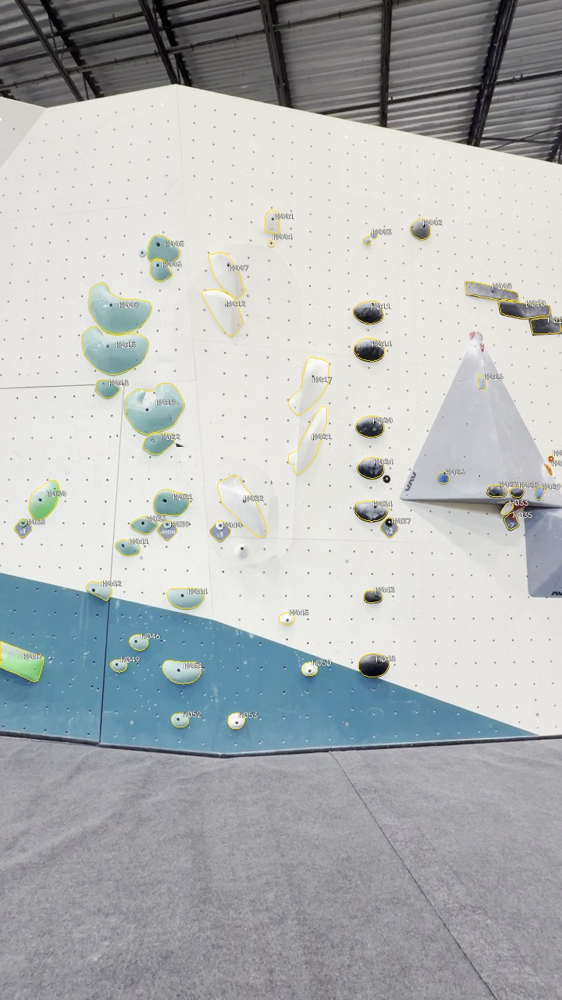

In [3]:
scene = build_scene(PROJECT_DIR, VIDEO_FILE, OUTPUTS_DIR, REFERENCE_FRAME, HOLD_SCORE_THRESHOLD)
print('Automatic hold candidates:', scene['candidate_count'])
print('Valid wall alignments:', scene['alignment_valid_frames'], '/', scene['alignment_total_frames'])
print('Reconstruction source frames:', scene['reconstruction']['source_frames'])
display(Image(filename=str(OUTPUTS_DIR / 'hold_mapping/candidates.jpg'), width=620))


## 4. Predict contacts and event times

The existing three-model temporal ensemble associates each limb with a hold, free state, or wall contact. Temporal decoding produces movement intervals. Release is the first free frame; arrival is the first new-contact frame. Original confidence and review flags are retained as evidence, while the authorized direct IK path bypasses the statistical acceptance gate. No retraining occurs in this notebook.


In [4]:
prediction, contacts = infer_contacts(PROJECT_DIR, VIDEO_FILE, OUTPUTS_DIR)
move_columns = ['moving_limb', 'from_hold', 'to_hold', 'before_frame', 'release_frame', 'arrival_frame', 'after_frame']
display(pd.DataFrame(prediction['moves']).reindex(columns=move_columns))
print('Movement proposals:', len(prediction['moves']))
print('Model-threshold coverage (not accuracy):', round(prediction['accepted_frame_fraction'], 3))


Reused verified automatic contacts.


,moving_limb,from_hold,to_hold,before_frame,release_frame,arrival_frame,after_frame
0,left_hand,H032,H017,88,96,111,118
1,left_hand,H017,H012,234,242,256,263
2,left_hand,H012,H007,371,379,379,386
3,left_hand,H007,H001,463,471,486,493
4,right_hand,H032,H021,35,43,55,62
5,right_hand,H021,H017,118,126,126,133
6,right_hand,H017,H007,296,304,324,331
7,right_hand,H007,H012,347,355,355,362
8,right_hand,H012,H001,401,409,428,435
9,left_foot,H053,H045,85,93,147,154


Movement proposals: 12
Model-threshold coverage (not accuracy): 0.762


## 5. Check metric geometry

Real target limb lengths require a wall scale and a segment suitable for the current 2D solver. A visually flat wall or a stable image alignment alone does not establish metric calibration. Set the inputs in Section 1 and rerun when measurements are available. Contact inference can complete without these measurements; metric retargeting cannot.


In [5]:
geometry = geometry_status(VIDEO_FILE, OUTPUTS_DIR, TARGET_HEIGHT_CM, RATIOS,
    PX_PER_CM, SINGLE_PANEL_CONFIRMED, SOURCE_CLIMBER_HEIGHT_CM, CALIBRATION_NOTE)
if geometry['blockers']:
    for reason in geometry['blockers']:
        print('Geometry pending:', reason)
else:
    print('Geometry inputs supplied; see the saved calibration note and IK residual checks.')


Geometry pending: PX_PER_CM is missing: local hole scales are not a whole-wall calibration.
Geometry pending: A suitable single-panel interval has not been established for the 2D solver.


## 6. Run automatic IK candidates

No manual BEFORE/AFTER form or repeated support-confirmation step is required. Compatible decoded contact sequences are passed directly to the existing continuous solver using the target body above. It currently requires one moving limb, three fixed hold supports, and complete observed poses and wall alignment. Unsupported sequences and missing calibration are reported explicitly; no synthetic support contacts are inserted.


In [6]:
direct_ik_plan = run_direct_ik(VIDEO_FILE, OUTPUTS_DIR,
    OUTPUTS_DIR / 'automatic/wholebody.npz', PROJECT_DIR / 'models/contact_v1',
    OUTPUTS_DIR / 'automatic/predictions', TARGET_HEIGHT_CM, RATIOS,
    PX_PER_CM, SINGLE_PANEL_CONFIRMED, enabled=AUTOMATIC_IK_ENABLED, execute=True)
print('Automatic IK enabled:', direct_ik_plan['enabled'])
print(f"Proposed: {direct_ik_plan['proposal_count']} | Solver-compatible: {direct_ik_plan['solver_compatible_count']} | Generated: {direct_ik_plan['generated_count']}")
display(direct_ik_table(direct_ik_plan))
for move in direct_ik_plan['moves']:
    if move['status'] == 'generated':
        display(Video(move['video_file'], embed=True, width=620))


Automatic IK enabled: True
Proposed: 12 | Solver-compatible: 3 | Generated: 0


,move,limb,transition,release,arrival,solver_compatible,status,reason
0,0,left_hand,H032 -> H017,96,111,False,unsupported_contact_schedule,left_foot: contact changes within the proposed...
1,1,left_hand,H017 -> H012,242,256,False,unsupported_contact_schedule,right_foot: wall_contact; the current solver r...
2,2,left_hand,H012 -> H007,379,379,False,unsupported_contact_schedule,No ordered contact / free / contact interval.;...
3,3,left_hand,H007 -> H001,471,486,True,pending_geometry,
4,4,right_hand,H032 -> H021,43,55,True,pending_geometry,
5,5,right_hand,H021 -> H017,126,126,False,unsupported_contact_schedule,No ordered contact / free / contact interval.;...
6,6,right_hand,H017 -> H007,304,324,False,unsupported_contact_schedule,right_foot: wall_contact; the current solver r...
7,7,right_hand,H007 -> H012,355,355,False,unsupported_contact_schedule,No ordered contact / free / contact interval.;...
8,8,right_hand,H012 -> H001,409,428,True,pending_geometry,
9,9,left_foot,H053 -> H045,93,147,False,unsupported_contact_schedule,left_hand: contact changes within the proposed...


## 7. Results and saved outputs

The contact preview below shows the original filmed climber, not the target body. Only videos generated in Section 6 are IK retargeting. The summary reports data coverage and solver readiness; trial3 has no ground-truth labels, so coverage must not be called contact accuracy. Intermediate artifacts and provenance are saved for restart; no duplicate notebook backup or default ZIP export is created.


In [7]:
summary = render_summary(VIDEO_FILE, OUTPUTS_DIR, prediction, contacts, direct_ik_plan)
display(pd.DataFrame([summary]).drop(columns=['geometry_blockers', 'interpretation', 'automatic_ik', 'preview_video']))
display(Video(summary['preview_video'], embed=True, width=620))
print('Contact preview: original climber; changing target height does not change this video.')
print('Summary:', OUTPUTS_DIR / 'state/run_summary.json')
print('Automatic IK details:', OUTPUTS_DIR / 'state/direct_ik_plan.json')
print('Source-frame mapping:', OUTPUTS_DIR / 'tables/source_frame_map.csv')


,frame_count,fps,hold_candidates,observed_pose_frames,alignment_valid_frames,model_threshold_coverage,movement_proposals,solver_compatible,generated_ik_videos,target_height_cm
0,503,30.0,53,503,503,0.761928,12,3,0,190


Contact preview: original climber; changing target height does not change this video.
Summary: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial3/state/run_summary.json
Automatic IK details: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial3/state/direct_ik_plan.json
Source-frame mapping: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial3/tables/source_frame_map.csv
